# EDA conjunto — Data4Cyber (S0–S5 + S1-alt)

Análisis exploratorio sobre las ** tablas de proceso** del release, unidas en un solo
`DataFrame` con la columna `escenario`.

**Cómo se ejecuta.** La celda 0 resuelve sola la ruta de datos: monta Drive si corre en
Colab y cae a `datasets/` si corre local. No hay rutas absolutas en ninguna otra celda.

In [15]:
# === 0. Configuración y carga de los escenarios ===

%matplotlib inline
import os


from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.width", 180)
pd.set_option("display.max_columns", 60)

# --- único punto con la ruta de datos: Drive en Colab, carpeta local en VS Code ---
# etiqueta legible -> archivo; S1-alt no sigue la regla dataset<etiqueta>.csv, por eso es explícito
ARCHIVOS = {
    "S0":     "datasetS0.csv",
    "S1":     "datasetS1.csv",
    "S1-alt": "datasetS1alt.csv",
    "S2":     "datasetS2.csv",
    "S3":     "datasetS3.csv",
    "S4":     "datasetS4.csv",
    "S5":     "datasetS5.csv",
}


from google.colab import drive
drive.mount("/content/gdrive/")
BASE =Path("/content/gdrive/MyDrive/TrabajoFinal/datasets/")


df = pd.concat(
    (pd.read_csv(BASE / archivo) for esc, archivo in ARCHIVOS.items()),
    ignore_index=True,
)

Drive already mounted at /content/gdrive/; to attempt to forcibly remount, call drive.mount("/content/gdrive/", force_remount=True).


In [16]:
# --- agrupación de columnas: dispositivo, tipo, fase ---
SIG_TIPO = {
    "uln1": "Tensión fase-neutro", "uln2": "Tensión fase-neutro", "uln3": "Tensión fase-neutro",
    "ull12": "Tensión fase-fase", "ull23": "Tensión fase-fase", "ull31": "Tensión fase-fase",
    "iln1": "Corriente de fase", "iln2": "Corriente de fase", "iln3": "Corriente de fase",
    "i_sum3": "Corriente de neutro",
    "pln1": "Potencia activa", "pln2": "Potencia activa", "pln3": "Potencia activa", "p_sum3": "Potencia activa",
    "sln1": "Potencia aparente", "sln2": "Potencia aparente", "sln3": "Potencia aparente", "s_sum3": "Potencia aparente",
    "qln1": "Potencia reactiva", "qln2": "Potencia reactiva", "qln3": "Potencia reactiva", "q_sum3": "Potencia reactiva",
    "cos_phi1": "Factor de potencia", "cos_phi2": "Factor de potencia", "cos_phi3": "Factor de potencia",
    "freq": "Frecuencia",
    "phase_seq": "Secuencia de fases",
    "realtime": "Marca de tiempo del equipo",
}
UNIDAD = {
    "Tensión fase-neutro": "V", "Tensión fase-fase": "V", "Corriente de fase": "A",
    "Corriente de neutro": "A", "Potencia activa": "W", "Potencia aparente": "VA",
    "Potencia reactiva": "var", "Factor de potencia": "—", "Frecuencia": "Hz",
    "Secuencia de fases": "—", "Marca de tiempo del equipo": "s",
    "SOC": "fracción 0-1", "Señal de precio": "EUR/kWh", "Contexto de escenario": "—",
    "Control / etiquetas": "—", "Desconocido": "?",
}
FASE = {"ull12": "L1-L2", "ull23": "L2-L3", "ull31": "L3-L1"}

def partir(c):
    if "." in c:
        dev, sig = c.split(".", 1)
    else:
        dev, sig = "(sin prefijo)", c
    return dev, sig

def tipo_de(dev, sig):
    if dev == "(sin prefijo)":
        return "Control / etiquetas"
    if dev.startswith("Battery-SOC"):
        return "SOC"
    if dev == "MQTT-Price-Signal":
        return "Señal de precio"
    if dev == "Profile":
        return "Contexto de escenario"
    return SIG_TIPO.get(sig, "Desconocido")

def fase_de(sig):
    if sig in FASE:
        return FASE[sig]
    if sig.endswith("sum3"):
        return "trifásica"
    if sig.endswith("1"):
        return "L1"
    if sig.endswith("2"):
        return "L2"
    if sig.endswith("3"):
        return "L3"
    return "—"

reg = []
for c in df.columns:
    dev, sig = partir(c)
    t = tipo_de(dev, sig)
    reg.append({"columna": c, "dispositivo": dev, "señal": sig,
                "tipo": t, "unidad": UNIDAD.get(t, "?"), "fase": fase_de(sig)})
cols = pd.DataFrame(reg)

print("columnas:", len(cols), "| dispositivos:", cols.dispositivo.nunique(), "| tipos:", cols.tipo.nunique())
print("\n--- por dispositivo ---")
por_dev = (cols.groupby("dispositivo")
           .agg(columnas=("columna", "size"), tipos=("tipo", lambda s: ", ".join(sorted(set(s)))))
           .sort_values("columnas", ascending=False))
display(por_dev)

columnas: 155 | dispositivos: 10 | tipos: 15

--- por dispositivo ---


,columnas,tipos
dispositivo,,
BSS-Inverter-AC-Meter,28,"Corriente de fase, Corriente de neutro, Factor..."
Load-B-AC-Meter,28,"Corriente de fase, Corriente de neutro, Factor..."
Substation-AC-Meter,28,"Corriente de fase, Corriente de neutro, Factor..."
Load-A-AC-Meter,28,"Corriente de fase, Corriente de neutro, Factor..."
PV-Inverter-AC-Meter,28,"Corriente de fase, Corriente de neutro, Factor..."
Profile,8,Contexto de escenario
(sin prefijo),4,Control / etiquetas
Battery-SOC-Reported,1,SOC
Battery-SOC-Reference,1,SOC


## 2. Datos Nulos

En este release **una celda vacía no es un cero ni un `NaN` imputado: es ausencia de valor de origen**.

In [17]:
# --- vacíos por columna y por fila ---

num = df.select_dtypes(include=[np.number])
no_num = [c for c in df.columns if c not in num.columns]
miss = df.isna()

print(f"columnas numéricas: {len(num.columns)} | no numéricas: {len(no_num)}")
if no_num:
    print("no numéricas:", no_num)

print(f"celdas vacías: {int(miss.values.sum()):,} de {miss.size:,} ({miss.values.mean()*100:.2f} %)")
print(f"filas con algún vacío: {int((miss.sum(axis=1) > 0).sum()):,} de {len(miss):,}")

por_col = miss.mean().mul(100).sort_values(ascending=False)
con_vacios = por_col[por_col > 0]
print(f"ncolumnas con al menos un vacío: {len(con_vacios)} de {len(por_col)}")
print("\ntop 15 columnas más incompletas (%):")
print(con_vacios.head(15).round(2).to_string())
#print(con_vacios.index.tolist())



columnas numéricas: 150 | no numéricas: 5
no numéricas: ['timestamp', 'attack_active', 'attack_phase', 'attack_phase_all', 'Profile.timestamp']
celdas vacías: 6,512 de 1,945,870 (0.33 %)
filas con algún vacío: 641 de 12,554
ncolumnas con al menos un vacío: 151 de 155

top 15 columnas más incompletas (%):
MQTT-Price-Signal.price_eur_per_kwh    4.25
Battery-SOC-Reported.soc_value         1.44
Profile.timestamp                      1.40
Profile.pv_active_kw                   1.40
Profile.load2_kw                       1.40
Profile.load1_kw                       1.40
Profile.ambient_temperature            1.40
Profile.total_irradiance               1.40
Profile.pv_input_kw                    1.40
Profile.pv_reactive_kvar               1.40
Battery-SOC-Reference.soc_value        0.39
BSS-Inverter-AC-Meter.qln2             0.25
BSS-Inverter-AC-Meter.qln3             0.25
BSS-Inverter-AC-Meter.realtime         0.25
BSS-Inverter-AC-Meter.s_sum3           0.25


 # Eliminar columnas sin aporte
 por ahora vamos a descartar las columas que involucren marcas temporales y etapas del ataque ya que no estamos interezados en analizar estas caracteristicas.
"

In [18]:
print(df.shape)
df = df.drop(columns=["attack_phase", "attack_phase_all","Profile.timestamp","timestamp"])
df = df.drop(columns=[c for c in df.columns if "realtime" in c ])
df = df.drop(columns=[c for c in df.columns if "phase_seq" in c ])
print(df.shape)


(12554, 155)
(12554, 141)


In [19]:
# Identificar columnas con al menos un valor nulo
columnas_con_nulos = df.columns[df.isna().any()]


# Filtrar filas que contienen nulos y mostrar solo esas columnas
filas_nulas_reducido = df.loc[df.isna().any(axis=1), columnas_con_nulos]
filas_nulas_reducido.head()

,BSS-Inverter-AC-Meter.cos_phi1,BSS-Inverter-AC-Meter.cos_phi2,BSS-Inverter-AC-Meter.cos_phi3,BSS-Inverter-AC-Meter.freq,BSS-Inverter-AC-Meter.i_sum3,BSS-Inverter-AC-Meter.iln1,BSS-Inverter-AC-Meter.iln2,BSS-Inverter-AC-Meter.iln3,BSS-Inverter-AC-Meter.p_sum3,BSS-Inverter-AC-Meter.pln1,BSS-Inverter-AC-Meter.pln2,BSS-Inverter-AC-Meter.pln3,BSS-Inverter-AC-Meter.q_sum3,BSS-Inverter-AC-Meter.qln1,BSS-Inverter-AC-Meter.qln2,BSS-Inverter-AC-Meter.qln3,BSS-Inverter-AC-Meter.s_sum3,BSS-Inverter-AC-Meter.sln1,BSS-Inverter-AC-Meter.sln2,BSS-Inverter-AC-Meter.sln3,BSS-Inverter-AC-Meter.ull12,BSS-Inverter-AC-Meter.ull23,BSS-Inverter-AC-Meter.ull31,BSS-Inverter-AC-Meter.uln1,BSS-Inverter-AC-Meter.uln2,BSS-Inverter-AC-Meter.uln3,Battery-SOC-Reference.soc_value,Battery-SOC-Reported.soc_value,Load-A-AC-Meter.cos_phi1,Load-A-AC-Meter.cos_phi2,...,Profile.pv_active_kw,Profile.pv_input_kw,Profile.pv_reactive_kvar,Profile.total_irradiance,Substation-AC-Meter.cos_phi1,Substation-AC-Meter.cos_phi2,Substation-AC-Meter.cos_phi3,Substation-AC-Meter.freq,Substation-AC-Meter.i_sum3,Substation-AC-Meter.iln1,Substation-AC-Meter.iln2,Substation-AC-Meter.iln3,Substation-AC-Meter.p_sum3,Substation-AC-Meter.pln1,Substation-AC-Meter.pln2,Substation-AC-Meter.pln3,Substation-AC-Meter.q_sum3,Substation-AC-Meter.qln1,Substation-AC-Meter.qln2,Substation-AC-Meter.qln3,Substation-AC-Meter.s_sum3,Substation-AC-Meter.sln1,Substation-AC-Meter.sln2,Substation-AC-Meter.sln3,Substation-AC-Meter.ull12,Substation-AC-Meter.ull23,Substation-AC-Meter.ull31,Substation-AC-Meter.uln1,Substation-AC-Meter.uln2,Substation-AC-Meter.uln3
0,-0.310502,-0.703539,-0.989501,50.008049,0.101279,0.39492,0.377298,0.421309,-53.832207,-18.320284,-16.559868,-18.952057,28.835691,-2.792666,-9.061968,3.146089,281.451599,93.153397,88.853355,99.444839,407.938171,408.500793,408.841309,235.879349,235.498993,236.037918,NaN,NaN,-0.778859,0.997305,...,NaN,NaN,NaN,NaN,-0.965705,-0.966816,-0.962146,50.005825,1.437780,9.847172,9.582252,9.602752,-5902.140137,-1999.145142,-1944.466309,-1958.528809,1616.824585,541.077271,517.283081,558.464233,6802.083984,2306.897217,2242.235840,2252.951416,405.437134,405.948944,406.069855,234.270035,233.998840,234.615189
1,-0.310502,-0.703539,-0.989501,50.008049,0.101279,0.39492,0.377298,0.421309,-53.832207,-18.320284,-16.559868,-18.952057,28.835691,-2.792666,-9.061968,3.146089,281.451599,93.153397,88.853355,99.444839,407.938171,408.500793,408.841309,235.879349,235.498993,236.037918,0.199597,NaN,-0.778859,0.997305,...,NaN,NaN,NaN,NaN,-0.965705,-0.966816,-0.962146,50.005825,1.437780,9.847172,9.582252,9.602752,-5902.140137,-1999.145142,-1944.466309,-1958.528809,1616.824585,541.077271,517.283081,558.464233,6802.083984,2306.897217,2242.235840,2252.951416,405.437134,405.948944,406.069855,234.270035,233.998840,234.615189
2,-0.310502,-0.703539,-0.989501,50.008049,0.101279,0.39492,0.377298,0.421309,-53.832207,-18.320284,-16.559868,-18.952057,28.835691,-2.792666,-9.061968,3.146089,281.451599,93.153397,88.853355,99.444839,407.938171,408.500793,408.841309,235.879349,235.498993,236.037918,0.199597,NaN,-0.778859,0.997305,...,NaN,NaN,NaN,NaN,-0.965705,-0.966816,-0.962146,50.005825,1.437780,9.847172,9.582252,9.602752,-5902.140137,-1999.145142,-1944.466309,-1958.528809,1616.824585,541.077271,517.283081,558.464233,6802.083984,2306.897217,2242.235840,2252.951416,405.437134,405.948944,406.069855,234.270035,233.998840,234.615189
3,-0.310502,-0.703539,-0.989501,50.008049,0.101279,0.39492,0.377298,0.421309,-53.832207,-18.320284,-16.559868,-18.952057,28.835691,-2.792666,-9.061968,3.146089,281.451599,93.153397,88.853355,99.444839,407.938171,408.500793,408.841309,235.879349,235.498993,236.037918,0.199597,NaN,-0.778859,0.997305,...,NaN,NaN,NaN,NaN,-0.965705,-0.966816,-0.962146,50.005825,1.437780,9.847172,9.582252,9.602752,-5902.140137,-1999.145142,-1944.466309,-1958.528809,1616.824585,541.077271,517.283081,558.464233,6802.083984,2306.897217,2242.235840,2252.951416,405.437134,405.948944,406.069855,234.270

Imputacion de datos nulos por la media

Puede ser que la imputacion por media elimine el sobrecalentamiento de los dispositivos(que termina rellenandose con ceros)

In [20]:
# 1. Irradiancia total
media_irradiance = df['Profile.total_irradiance'].mean()
df['Profile.total_irradiance'] = df['Profile.total_irradiance'].fillna(media_irradiance)

# 2. Temperatura ambiente
media_temp = df['Profile.ambient_temperature'].mean()
df['Profile.ambient_temperature'] = df['Profile.ambient_temperature'].fillna(media_temp)

# 3. Señal de precio MQTT
media_price = df['MQTT-Price-Signal.price_eur_per_kwh'].mean()
df['MQTT-Price-Signal.price_eur_per_kwh'] = df['MQTT-Price-Signal.price_eur_per_kwh'].fillna(media_price)

# 4. SOC de referencia de batería
media_soc_ref = df['Battery-SOC-Reference.soc_value'].mean()
df['Battery-SOC-Reference.soc_value'] = df['Battery-SOC-Reference.soc_value'].fillna(media_soc_ref)

# 5. SOC reportado de batería
media_soc_rep = df['Battery-SOC-Reported.soc_value'].mean()
df['Battery-SOC-Reported.soc_value'] = df['Battery-SOC-Reported.soc_value'].fillna(media_soc_rep)

# 6. Carga de perfil 1
media_load1 = df['Profile.load1_kw'].mean()
df['Profile.load1_kw'] = df['Profile.load1_kw'].fillna(media_load1)

# 7. Carga de perfil 2
media_load2 = df['Profile.load2_kw'].mean()
df['Profile.load2_kw'] = df['Profile.load2_kw'].fillna(media_load2)

media_active_kw = df['Profile.pv_active_kw'].mean()
df['Profile.pv_active_kw'] = df['Profile.pv_active_kw'].fillna(media_active_kw)

media_input_kw = df['Profile.pv_input_kw'].mean()
df['Profile.pv_input_kw'] = df['Profile.pv_input_kw'].fillna(media_input_kw)

media_reactive_kvar = df['Profile.pv_reactive_kvar'].mean()
df['Profile.pv_reactive_kvar'] = df['Profile.pv_reactive_kvar'].fillna(media_reactive_kvar)

columnas_media = [
    "Profile.total_irradiance",
    "Profile.ambient_temperature",
    "MQTT-Price-Signal.price_eur_per_kwh",
    "Battery-SOC-Reference.soc_value",
    "Battery-SOC-Reported.soc_value",
    "Profile.load1_kw",
    "Profile.load2_kw",
    "Profile.pv_active_kw",
    "Profile.pv_input_kw",
    "Profile.pv_reactive_kvar",
    "BSS-Inverter-AC-Meter.cos_phi2",
    "BSS-Inverter-AC-Meter.cos_phi1",
    "BSS-Inverter-AC-Meter.cos_phi3",
    "BSS-Inverter-AC-Meter.freq",
    "BSS-Inverter-AC-Meter.iln1",
    "BSS-Inverter-AC-Meter.i_sum3",
    "BSS-Inverter-AC-Meter.p_sum3",
    "BSS-Inverter-AC-Meter.pln1",
    "BSS-Inverter-AC-Meter.iln2",
    "BSS-Inverter-AC-Meter.iln3",
    "BSS-Inverter-AC-Meter.pln2",
    "BSS-Inverter-AC-Meter.pln3",
    "BSS-Inverter-AC-Meter.qln1",
    "BSS-Inverter-AC-Meter.q_sum3",
    "Substation-AC-Meter.sln2",
    'Load-A-AC-Meter.cos_phi3', 
    'Load-A-AC-Meter.freq', 
    'BSS-Inverter-AC-Meter.uln1', 
    'BSS-Inverter-AC-Meter.ull31', 
    'BSS-Inverter-AC-Meter.uln3', 
    'BSS-Inverter-AC-Meter.uln2', 
    'BSS-Inverter-AC-Meter.ull12', 
    'BSS-Inverter-AC-Meter.ull23', 
    'BSS-Inverter-AC-Meter.sln3', 
    'BSS-Inverter-AC-Meter.sln2', 
    'BSS-Inverter-AC-Meter.s_sum3', 
    'BSS-Inverter-AC-Meter.sln1', 
    'BSS-Inverter-AC-Meter.qln2', 
    'BSS-Inverter-AC-Meter.qln3', 
    'Substation-AC-Meter.sln3', 
    'Substation-AC-Meter.ull12', 
    'Substation-AC-Meter.iln3', 
    'Substation-AC-Meter.iln2', 
    'PV-Inverter-AC-Meter.cos_phi1', 
    'PV-Inverter-AC-Meter.cos_phi2', 
    'PV-Inverter-AC-Meter.cos_phi3', 
    'PV-Inverter-AC-Meter.freq', 
    'PV-Inverter-AC-Meter.iln3', 
    'PV-Inverter-AC-Meter.i_sum3', 
    'PV-Inverter-AC-Meter.iln1', 
    'PV-Inverter-AC-Meter.iln2', 
    'PV-Inverter-AC-Meter.pln1', 
    'PV-Inverter-AC-Meter.p_sum3', 
    'Load-A-AC-Meter.cos_phi2', 
    'Load-A-AC-Meter.cos_phi1', 
    'Load-A-AC-Meter.p_sum3', 
    'Load-A-AC-Meter.pln1', 
    'Load-A-AC-Meter.pln2', 
    'Load-A-AC-Meter.pln3', 
    'Load-A-AC-Meter.i_sum3', 'Load-A-AC-Meter.iln1', 'Load-A-AC-Meter.iln2', 'Load-A-AC-Meter.iln3', 'Load-A-AC-Meter.q_sum3', 'Load-A-AC-Meter.qln1', 'Load-A-AC-Meter.qln2', 'Load-A-AC-Meter.qln3', 'Load-A-AC-Meter.sln3', 'Load-A-AC-Meter.sln2', 'Load-A-AC-Meter.sln1', 'Load-A-AC-Meter.s_sum3', 'Load-B-AC-Meter.iln2', 'Load-B-AC-Meter.iln3', 'Load-B-AC-Meter.p_sum3', 'Load-B-AC-Meter.pln1', 'Load-A-AC-Meter.ull12', 'Load-A-AC-Meter.ull23', 'Load-A-AC-Meter.ull31', 'Load-A-AC-Meter.uln1', 'Load-A-AC-Meter.uln2', 'Load-A-AC-Meter.uln3', 'Load-B-AC-Meter.cos_phi1', 'Load-B-AC-Meter.cos_phi2', 'Load-B-AC-Meter.cos_phi3', 'Load-B-AC-Meter.freq', 'Load-B-AC-Meter.i_sum3', 'Load-B-AC-Meter.iln1', 'Load-B-AC-Meter.qln2', 'Load-B-AC-Meter.qln3', 'Load-B-AC-Meter.s_sum3', 'Load-B-AC-Meter.sln1', 'Load-B-AC-Meter.pln2', 'Load-B-AC-Meter.pln3', 'Load-B-AC-Meter.q_sum3', 'Load-B-AC-Meter.qln1', 'Load-B-AC-Meter.sln2', 'Load-B-AC-Meter.sln3', 'Load-B-AC-Meter.ull12', 'Load-B-AC-Meter.ull23', 'Load-B-AC-Meter.uln3', 'Load-B-AC-Meter.uln2', 'Load-B-AC-Meter.uln1', 'Load-B-AC-Meter.ull31', 'Substation-AC-Meter.uln3', 'Substation-AC-Meter.uln1', 'Substation-AC-Meter.ull23', 'Substation-AC-Meter.ull31', 'Substation-AC-Meter.iln1', 'Substation-AC-Meter.i_sum3', 'Substation-AC-Meter.freq', 'Substation-AC-Meter.cos_phi3', 'Substation-AC-Meter.p_sum3', 'Substation-AC-Meter.pln1', 'Substation-AC-Meter.qln3', 'Substation-AC-Meter.qln2', 'Substation-AC-Meter.qln1', 'Substation-AC-Meter.q_sum3', 'PV-Inverter-AC-Meter.pln2', 'PV-Inverter-AC-Meter.pln3', 'PV-Inverter-AC-Meter.sln3', 'PV-Inverter-AC-Meter.q_sum3', 'PV-Inverter-AC-Meter.qln1', 'PV-Inverter-AC-Meter.qln2', 'PV-Inverter-AC-Meter.qln3', 'PV-Inverter-AC-Meter.s_sum3', 'PV-Inverter-AC-Meter.sln1', 'PV-Inverter-AC-Meter.sln2', 'PV-Inverter-AC-Meter.uln1', 'PV-Inverter-AC-Meter.ull12', 'PV-Inverter-AC-Meter.ull23', 'PV-Inverter-AC-Meter.ull31', 'PV-Inverter-AC-Meter.uln3', 'PV-Inverter-AC-Meter.uln2', 'Substation-AC-Meter.cos_phi2', 'Substation-AC-Meter.cos_phi1', 'Substation-AC-Meter.uln2', 'Substation-AC-Meter.sln1', 'Substation-AC-Meter.s_sum3', 'Substation-AC-Meter.pln2', 'Substation-AC-Meter.pln3'

]

antes = int(df[columnas_media].isna().sum().sum())
for col in columnas_media:
    df[col] = df[col].fillna(df[col].mean())


In [21]:
# === 1. Exportar el dataset modificado ===

# --- guarda en CSV el df ya modificado, junto a los originales y con nombre propio ---
ruta_salida = os.path.join(BASE, "extras/dataset_modificado.csv")
df.to_csv(ruta_salida, index=False)

print("archivo:", ruta_salida)
print("filas:", len(df), "| columnas:", df.shape[1])
print("celdas vacías restantes:", int(df.isna().sum().sum()))
print("columnas con vacíos:", int((df.isna().sum() > 0).sum()))

archivo: /content/gdrive/MyDrive/TrabajoFinal/datasets/extras/dataset_modificado.csv
filas: 12554 | columnas: 141
celdas vacías restantes: 0
columnas con vacíos: 0



# PCA
 1 = Estandarizamos para
| 2 | Estructura lineal | Pearson vs Spearman; scatter de los pares con \|r\| alto | Coinciden en los pares fuertes | Kernel PCA o transformar |
| 3 | Correlaciones no triviales | Bartlett (H0: R = I) + KMO | Bartlett p < 0.05 y KMO ≥ 0.6 | PCA no aporta; usar variables originales |
| 4 | Sin outliers extremos | Boxplots/IQR; Mahalanobis (D² vs chi², p gl) con MinCovDet | Pocos casos extremos, no sistemáticos | PCA robusta o winsorizar |
| 5 | Matriz numérica completa | Nulos por columna/fila; tipos | 0 NaN y solo numéricas | Descartar bloque de calentamiento o imputar (explícito) |
| 6 | Sin columnas constantes | `std == 0` | 0 columnas constantes | Descartarlas |
| 7 | n > p | Filas vs columnas | n > p (12.554 >> 140) | Reducir variables o regularizar 

In [22]:
from sklearn.preprocessing import StandardScaler
Y=df["attack_active"]
X=df.drop(["attack_active"],axis=1)

#Estandarización
sc = StandardScaler()
Xs = sc.fit_transform(X)

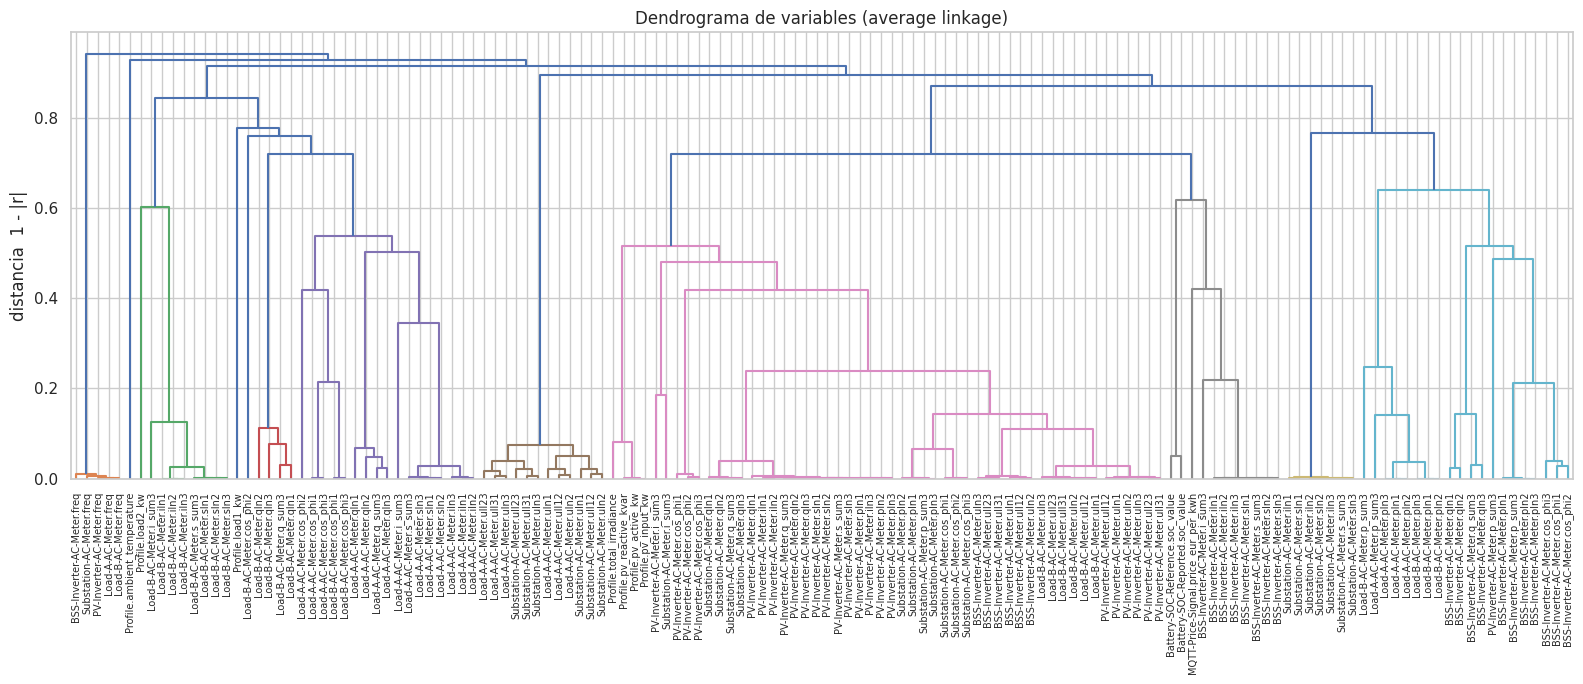

In [23]:
# === 7. Dendrograma de columnas correlacionadas ===

from scipy.cluster.hierarchy import linkage, dendrogram
from scipy.spatial.distance import squareform

# --- correlación entre numéricas; |r| porque la relación puede ser inversa ---
X_num = df.select_dtypes(include=[np.number])
R = X_num.corr().abs().fillna(0)

# --- distancia 1-|r| y clustering jerárquico (average) ---
D = (1 - R).to_numpy()
np.fill_diagonal(D, 0)
Z = linkage(squareform(D, checks=False), method="average")

# --- dendrograma con los nombres de columna en las hojas ---
fig, ax = plt.subplots(figsize=(16, 7))
dendrogram(Z, labels=X_num.columns.tolist(), leaf_rotation=90, leaf_font_size=7, ax=ax)
ax.set_ylabel("distancia  1 - |r|")
ax.set_title("Dendrograma de variables (average linkage)")
plt.tight_layout()
plt.show()

In [24]:
from scipy.cluster.hierarchy import fcluster
etiquetas = fcluster(Z, t=0.3, criterion="distance")
bloques = pd.Series(etiquetas, index=X.columns)

print("bloques encontrados:", bloques.nunique())
print("columnas por bloque (las 10 más grandes):")
print(bloques.value_counts().head(10))
lista_grupos = [grupo.index.tolist() for _, grupo in bloques.groupby(bloques)]
print(lista_grupos)

bloques encontrados: 25
columnas por bloque (las 10 más grandes):
16    43
12    12
18     8
21     8
2      8
8      7
23     7
20     7
1      5
22     4
Name: count, dtype: int64
[['BSS-Inverter-AC-Meter.freq', 'Load-A-AC-Meter.freq', 'Load-B-AC-Meter.freq', 'PV-Inverter-AC-Meter.freq', 'Substation-AC-Meter.freq'], ['Load-B-AC-Meter.i_sum3', 'Load-B-AC-Meter.iln1', 'Load-B-AC-Meter.iln2', 'Load-B-AC-Meter.iln3', 'Load-B-AC-Meter.s_sum3', 'Load-B-AC-Meter.sln1', 'Load-B-AC-Meter.sln2', 'Load-B-AC-Meter.sln3'], ['Profile.load2_kw'], ['Load-B-AC-Meter.q_sum3', 'Load-B-AC-Meter.qln1', 'Load-B-AC-Meter.qln2', 'Load-B-AC-Meter.qln3'], ['Load-A-AC-Meter.cos_phi1', 'Load-A-AC-Meter.cos_phi3', 'Load-B-AC-Meter.cos_phi1', 'Load-B-AC-Meter.cos_phi3'], ['Load-A-AC-Meter.cos_phi2'], ['Load-A-AC-Meter.q_sum3', 'Load-A-AC-Meter.qln1', 'Load-A-AC-Meter.qln2', 'Load-A-AC-Meter.qln3'], ['Load-A-AC-Meter.iln1', 'Load-A-AC-Meter.iln2', 'Load-A-AC-Meter.iln3', 'Load-A-AC-Meter.s_sum3', 'Load-A-AC-Meter.

In [25]:
import sklearn
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split

grupos=[]
pca = PCA(n_components=0.95, random_state=0)
x_pca_test=[]
x_pca_train=[]
Xs = pd.DataFrame(Xs, columns=X.columns)
X_train, X_test, Y_train, Y_test = sklearn.model_selection.train_test_split(Xs, Y, test_size = 0.25, random_state = 0)
for i, cols in enumerate(lista_grupos):
    if len(cols) != 1:
        #pca = PCA(n_components=0.95)
        x_pca_train.append(pca.fit_transform(X_train[cols]))
        x_pca_test.append(pca.transform(X_test[cols]))
    else:
        x_pca_test.append(X_test[cols])
        x_pca_train.append(X_train[cols])
print(list(map(lambda x: x.shape[1], x_pca_test)))
print(list(map(lambda x: x.shape[1], x_pca_train)))
print(len(x_pca_train))
print(x_pca_train[0])

[1, 1, 1, 2, 2, 1, 1, 1, 1, 1, 1, 2, 1, 2, 1, 3, 1, 1, 1, 1, 2, 2, 2, 1, 1]
[1, 1, 1, 2, 2, 1, 1, 1, 1, 1, 1, 2, 1, 2, 1, 3, 1, 1, 1, 1, 2, 2, 2, 1, 1]
25
[[-1.34015728]
 [-1.91751109]
 [ 2.42996642]
 ...
 [-1.38600292]
 [-2.15173889]
 [-0.5455239 ]]


In [26]:
# === 8. Ensamblar el dataset reducido (bloques PCA + columnas sueltas) ===
# --- hstack de todos los bloques y re-armado como DataFrame con el índice original ---
X_train_red = pd.DataFrame(np.hstack([np.asarray(b) for b in x_pca_train]),
                           index=X_train.index)
X_test_red  = pd.DataFrame(np.hstack([np.asarray(b) for b in x_pca_test]),
                           index=X_test.index)

print("train:", X_train_red.shape, "| test:", X_test_red.shape)


train: (9415, 34) | test: (3139, 34)
